In [1]:
display("text/html", "<style>.container { width:100% !important; }</style>")

# Sample BBO of the oral microbial communities

In [1]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM, BlackBoxOptim, Distances, Printf

In [2]:
Plots.theme(:dao)

In [3]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

In [4]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1];

In [5]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
# first split on classification
gd1 = groupby(read_data, :classification);

In [6]:
gd1[2]

Row,otu_id,count,project_id,sample_id,run_id,nreads,classification
,Int64,Float64,String15,String15,String15,Float64,String
1,968675,1.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
2,932696,1.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
3,1098340,3.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
4,1111525,1.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
5,905769,1.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
6,1505940,1.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
7,1083194,2.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
8,4471251,1.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
9,865469,3.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL


For each classification, split up on the sample.

In [7]:
gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

Now, we only want to work with a simple system to start. `Oral` at index 2 is a good system that nicely follows Heaps' law.

In [8]:
gd_classes[2];

In [9]:
data = gd_classes[2];

We need to get the size of each of these systems.

In [10]:
# first split on classification (microbiome type)
gd_test = groupby(read_data, :classification);
# for the group of interest (given by data_ind) split up the samples
data_test = groupby(gd_test[2], :sample_id);

In [11]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

130072.0

Let's choose the smallest of these systems as the initial condition.

In [12]:
argmin(sizes)

59

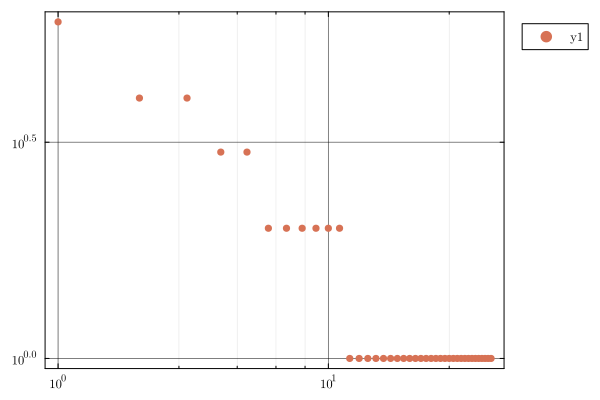

In [13]:
ic_sys = data[argmin(sizes)]
ic_sys = sort(ic_sys[!,:count],rev=true)
scatter(ic_sys, xaxis = :log, yaxis = :log)

Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [14]:
guess_sim = dsim.create_cell(-0.1,0.93,10.0,convert(Int64,maximum(sizes)), ic_sys, :pdf)

1739-element Vector{Float64}:
 4755.0
 3678.0
 3043.0
 2719.0
 2714.0
 2210.0
 2099.0
 2095.0
 2088.0
 1895.0
 1849.0
 1767.0
 1720.0
    ⋮
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0

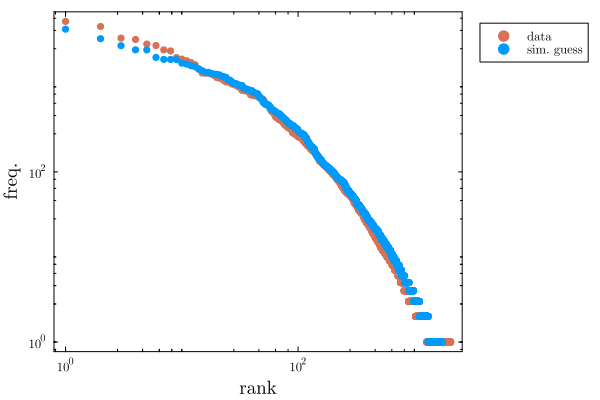

In [15]:
scatter(sort(data[argmax(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data")
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

Pretty quickly, we can get something that is bang on!

## Now, need to formalize this a little bit.

- Calculate $p_0$ from the diversity curve and initial condition.
- Set up a simple calibration procedure to go from the smallest to the largest ecosystem.
- Generalize this to do the top 10 ecosystems in terms of size. 

In [16]:
logxs = log10.(sum.([x[!,:count] for x in data]))
logys = log10.(length.([x[!,:count] for x in data]));

In [17]:
df = DataFrame(y = logys, x = logxs);

In [18]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
────────────────────────────────────────────────────────────────────────
                Coef.  Std. Error      t  Pr(>|t|)  Lower 95%  Upper 95%
────────────────────────────────────────────────────────────────────────
(Intercept)  0.708404   0.0473157  14.97    <1e-25   0.614417   0.802391
x            0.53238    0.0111613  47.70    <1e-65   0.51021    0.554551
────────────────────────────────────────────────────────────────────────

In [19]:
a,b = coef(glm)

2-element Vector{Float64}:
 0.7084042943965811
 0.532380399267376

Following the SI of the PNAS paper...

In [20]:
θ = 2+1/(b-1);

In [21]:
ic_sys;

In [22]:
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)))
p0_guess = α*b*10^a; 

This value of $p_0$ seems to be quite the underestimate. Especially so when the noise in the Heaps' law is expected to be high. Perhaps let's use ten times this value as an upper bound of $p_0$, and have the lower bound as $p_0$. No need to infer $p_0$ in log-space. 

# Set-up the BBO

In [23]:
# padding function
function pad_rdist(d1, d2)
    min_not_0 = minimum(filter!(x->x!=0,vcat(d1, d2))); # so that the padded values are not exactly zero
    n = max(length(d1), length(d2));
    d1_padded = vcat(d1, ones(n - length(d1))*min_not_0/10); # divide by 10, so as not to punish the distance too badly (could make things too stochastic).
    d2_padded = vcat(d2, ones(n - length(d2))*min_not_0/10);
    return d1_padded, d2_padded, abs(length(d1) - length(d2));
end;

In [28]:
function ibb_fn(S::Array{Float64,1})
    # assign values of model pars
    θ, γ = S[1:2];
    # simulate the organization and collect the norm rf distribution
    osim = dsim.create_cell(θ,γ,p0_guess,floor(Int64,N), ic_sys, :pdf) # need to define N
    df_norm = data_rf/sum(data_rf) # need to define data_rf
    osim_norm = osim/sum(osim)

    # need to pad the distributions 
    df_norm_pad, osim_norm_pad = pad_rdist(df_norm,osim_norm)
    # find the logarithm of elements for the distance calculation
    df_norm_pad_log, osim_norm_pad_log = log.(df_norm_pad), log.(osim_norm_pad)
    euc_log = euclidean(df_norm_pad_log, osim_norm_pad_log)
    return euc_log
end

ibb_fn (generic function with 1 method)

Define the relevant variable.

In [29]:
data_rf = sort(data[argmax(sizes)][!,:count],rev=true)
N = sum(data_rf);

In [30]:
iSRange = [(0.0,1.0),(0.2,1.5)];
iopts = bbsetup(ibb_fn; Method = :adaptive_de_rand_1_bin_radiuslimited, SearchRange = iSRange, 
            NumDimensions = 2, MaxTime = 100.0, PopulationSize = 50, TraceMode=:silent);

In [31]:
ires = bboptimize(iopts);
iopt_par = best_candidate(ires);
ifitness = best_fitness(ires);

In [32]:
iopt_par

2-element Vector{Float64}:
 0.05782468551113085
 1.1067224073801296

In [38]:
guess_sim = dsim.create_cell(iopt_par...,p0_guess,convert(Int64,maximum(sizes)), ic_sys, :pdf)

1919-element Vector{Float64}:
 26326.0
 14169.0
 11493.0
  9376.0
  6364.0
  5015.0
  4659.0
  4619.0
  4075.0
  4039.0
  3569.0
  3440.0
  2761.0
     ⋮
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0

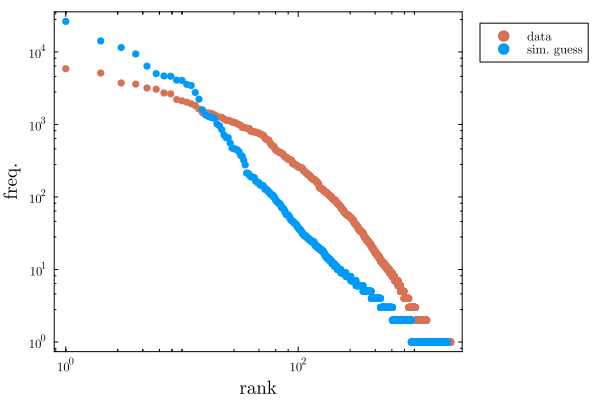

In [39]:
scatter(sort(data[argmax(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data")
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

Obviously not a lot of time to find the optimum, but seems like it works well enough for the full trial run.

## Practicalities

### 1. Need to find the top ten Oral microbiomes by size.

In [35]:
sizes[40]

86721.0

In [36]:
top10inds = sortperm(sizes, rev = true)[1:10];

In [37]:
sort(vcat(data[top10inds[2]][!,:count]),rev=true)

2533-element Vector{Float64}:
 9515.0
 3897.0
 3696.0
 3215.0
 2364.0
 1779.0
 1567.0
 1534.0
 1504.0
 1443.0
 1382.0
 1356.0
 1295.0
    ⋮
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0

# Test of the code for supercomp.

In [40]:
# microbiome number
data_ind = 2;

In [41]:
# import data 
read_data = CSV.read("$(homedir())/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)

Row,otu_id,count,project_id,sample_id,run_id,nreads,classification
,Int64,Float64,String15,String15,String15,Float64,String
1,107380,7.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
2,149885,1.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
3,118090,6.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
4,103181,854.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
5,83222,1.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
6,57104,9.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
7,219738,2.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
8,242743,1.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
9,176063,4.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater


In [42]:
# first split on classification (microbiome type)
gd = groupby(read_data, :classification);
# for the group of interest (given by data_ind) split up the samples
data = groupby(gd[data_ind], :sample_id)

# get the top ten microbiomes by size
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
top10inds = sortperm(sizes, rev = true)[1:10];

# need to get the initial conditions (smallest ecosystem in the data for that class)
ic_sys = data[argmin(sizes)]
ic_sys = sort(ic_sys[!,:count], rev=true)

# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a;

In [43]:
# the vectors that will store the required values of θ, γ
θ_vec_all = Vector{Union{Missing, Float64}}(undef, 10); θ_vec_all .= 0.0;
γ_vec_all = Vector{Union{Missing, Float64}}(undef, 10); γ_vec_all .= 0.0;
fitness_all = Vector{Union{Missing, Float64}}(undef, 10); fitness_all .= 0.0;

In [44]:
# padding function
function pad_rdist(d1, d2)
    min_not_0 = minimum(filter!(x->x!=0,vcat(d1, d2))); # so that the padded values are not exactly zero
    n = max(length(d1), length(d2));
    d1_padded = vcat(d1, ones(n - length(d1))*min_not_0/10); # divide by 10, so as not to punish the distance too badly (could make things too stochastic).
    d2_padded = vcat(d2, ones(n - length(d2))*min_not_0/10);
    return d1_padded, d2_padded, abs(length(d1) - length(d2));
end;

In [51]:
for i in 1:10
    # relabel the data
    data_rf = sort(vcat(data[top10inds[i]][!,:count]), rev=true)
    N = sum(data_rf)

    function ibb_fn(S::Array{Float64,1})
        # assign values of model pars
        θ, γ = S[1:2];
        # simulate the organization and collect the norm rf distribution
        osim = dsim.create_cell(θ,γ,p0_guess, floor(Int64,N), ic_sys, :pdf)
        df_norm = data_rf/sum(data_rf)
        osim_norm = osim/sum(osim)

        # need to pad the distributions 
        df_norm_pad, osim_norm_pad = pad_rdist(df_norm, osim_norm)
        # find the logarithm of elements for the distance calculation
        df_norm_pad_log, osim_norm_pad_log = log.(df_norm_pad), log.(osim_norm_pad)
        euc_log = euclidean(df_norm_pad_log, osim_norm_pad_log)
        return euc_log
    end

    println("Starting optimizations.")

    # run the opt
    iSRange = [(-0.6,1.0),(0.2,1.5)];
    iopts = bbsetup(ibb_fn; Method = :adaptive_de_rand_1_bin_radiuslimited, SearchRange = iSRange, 
            NumDimensions = 2, MaxTime = 10.0, PopulationSize = 50, TraceMode=:silent); # 1 day: 86400.0
    ires = bboptimize(iopts);
    iopt_par = best_candidate(ires);
    ifitness = best_fitness(ires);

    # store the pars
    θ_vec_all[i] = iopt_par[1]; γ_vec_all[i] = iopt_par[2]; fitness_all[i] = ifitness;
    @printf "Calibration %d out of %d now done, giving parameters θ = %.3f, γ = %.3f with fitness %.3f." i 10 θ_vec_all[i] γ_vec_all[i] ifitness
    println("")
end

Starting optimizations.
Calibration 1 out of 10 now done, giving parameters θ = 0.242, γ = 1.177 with fitness 80.367.
Starting optimizations.
Calibration 2 out of 10 now done, giving parameters θ = -0.588, γ = 0.848 with fitness 56.238.
Starting optimizations.
Calibration 3 out of 10 now done, giving parameters θ = -0.161, γ = 0.709 with fitness 69.241.
Starting optimizations.
Calibration 4 out of 10 now done, giving parameters θ = -0.452, γ = 0.665 with fitness 81.218.
Starting optimizations.
Calibration 5 out of 10 now done, giving parameters θ = -0.132, γ = 1.056 with fitness 46.127.
Starting optimizations.
Calibration 6 out of 10 now done, giving parameters θ = 0.216, γ = 0.738 with fitness 68.910.
Starting optimizations.
Calibration 7 out of 10 now done, giving parameters θ = 0.204, γ = 0.967 with fitness 83.602.
Starting optimizations.
Calibration 8 out of 10 now done, giving parameters θ = -0.258, γ = 0.463 with fitness 90.180.
Starting optimizations.
Calibration 9 out of 10 now

In [52]:
df_out = DataFrame(theta=θ_vec_all, gamma=γ_vec_all, fitness = fitness_all);
CSV.write("$(homedir())/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed/eco-calib-$(data_ind).csv", df_out)
pwd()

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations"